# Segment Effects

Tests the six segment hypotheses in the [analysis plan](../analysis_plan.md). The results feed the targeting rule for challenge questions 3 and 4, and H2 also answers questions 5 and 8.

Each hypothesis is tested with one regression that includes an interaction term. **The interaction coefficient is the difference in the email effect between the two segments.** Standard errors are robust (HC3). The Holm correction is applied after all six tests are run.

## How to read the tables

Each hypothesis fits `outcome = b0 + b1 × email + b2 × segment + b3 × email × segment`, where `segment` is 0 or 1. Each hypothesis shows two tables.

**Table 1, the raw regression output for spend:**

| Coefficient | Meaning |
| --- | --- |
| b0 | Mean spend in segment 0 without email. It is a baseline, and its p-value is not of interest. |
| b1 | Email effect in segment 0 |
| b2 | Difference between the segments without email. It describes the customers, not the email. |
| **b3** | **Difference in the email effect between the segments. Its p-value decides the hypothesis.** |

**Table 2, the effect in each segment, for all three metrics:**

- The first row is b1, and the third row is b3. Both are copied from the regression, with the same values and p-values as Table 1.
- The second row is b1 + b3, the email effect in segment 1. **It is not a regression coefficient, so it is computed separately** with a test of the sum: the estimate is b1 + b3, and its standard error comes from Var(b1) + Var(b3) + 2 × Cov(b1, b3). Because b3 is defined relative to b1, their errors cancel, and **the result equals comparing email and no email within segment 1 alone.** Its p-value therefore cannot be read from the p-values of b1 and b3.

**Each result note follows the same order:** the difference in effect (b3), which decides the hypothesis; the effect in each segment (b1 and b1 + b3); the difference without email (b2); the secondary metrics; and a one-sentence summary.

In [1]:
import pandas as pd
import statsmodels.formula.api as smf

df = pd.read_csv("../data/hillstrom.csv")
df["email"] = (df["segment"] != "No E-Mail").astype(int)

METRICS = ["spend", "conversion", "visit"]


def raw_coefficients(data, treatment, segment, labels, metric="spend"):
    """Fit outcome ~ treatment * segment and return the four regression coefficients with their meaning."""
    model = smf.ols(f"{metric} ~ {treatment} * {segment}", data).fit(cov_type="HC3")
    ci = model.conf_int()
    meaning = {
        "Intercept": f"b0: mean {metric} for {labels[0]}, no email",
        treatment: f"b1: email effect for {labels[0]}",
        segment: f"b2: difference without email, {labels[1]} minus {labels[0]}",
        f"{treatment}:{segment}": "b3: difference in email effect (interaction)",
    }
    table = pd.DataFrame({"value": model.params, "low": ci[0], "high": ci[1], "p_value": model.pvalues})
    return table.rename(index=meaning)


def interaction_test(data, treatment, segment, labels):
    """Fit outcome ~ treatment * segment for each metric and report the effect in each segment and their difference.

    labels maps the segment values 0 and 1 to readable names.
    """
    rows = []
    for metric in METRICS:
        model = smf.ols(f"{metric} ~ {treatment} * {segment}", data).fit(cov_type="HC3")
        tests = {
            f"effect for {labels[0]}": f"{treatment} = 0",
            f"effect for {labels[1]}": f"{treatment} + {treatment}:{segment} = 0",
            "difference (interaction)": f"{treatment}:{segment} = 0",
        }
        for label, hypothesis in tests.items():
            test = model.t_test(hypothesis)
            low, high = test.conf_int(alpha=0.05)[0]
            rows.append({"metric": metric, "estimate": label, "value": float(test.effect[0]),
                         "low": low, "high": high, "p_value": float(test.pvalue)})
    return pd.DataFrame(rows).set_index(["metric", "estimate"])

## H1: Recency

**Hypothesis:** the email effect is larger for customers who last purchased 1 to 3 months ago than for those who last purchased 4 to 12 months ago. The Mens and Womens groups are pooled.

Model: `spend ~ email + recent + email:recent`, where `recent` = 1 for 1 to 3 months.

In [2]:
df["recent"] = (df["recency"] <= 3).astype(int)
H1_LABELS = {0: "4-12 months (recent = 0)", 1: "1-3 months (recent = 1)"}

counts = pd.crosstab(df["recent"].map(H1_LABELS), df["email"].map({0: "No email", 1: "Email"}), margins=True)
counts.index.name, counts.columns.name = "Last purchase", None
counts

,Email,No email,All
Last purchase,,,
1-3 months (recent = 1),14955,7438,22393
4-12 months (recent = 0),27739,13868,41607
All,42694,21306,64000


In [3]:
display(raw_coefficients(df, "email", "recent", H1_LABELS).round(4))

h1 = interaction_test(df, "email", "recent", H1_LABELS)
h1.round(4)

,value,low,high,p_value
"b0: mean spend for 4-12 months (recent = 0), no email",0.4968,0.3223,0.6714,0.0000
b1: email effect for 4-12 months (recent = 0),0.5389,0.2923,0.7855,0.0000
"b2: difference without email, 1-3 months (recent = 1) minus 4-12 months (recent = 0)",0.4467,0.0957,0.7977,0.0126
b3: difference in email effect (interaction),0.1638,-0.3346,0.6622,0.5194


value     low    high  \
metric     estimate                                                      
spend      effect for 4-12 months (recent = 0)  0.5389  0.2923  0.7855   
           effect for 1-3 months (recent = 1)   0.7027  0.2696  1.1358   
           difference (interaction)             0.1638 -0.3346  0.6622   
conversion effect for 4-12 months (recent = 0)  0.0049  0.0034  0.0064   
           effect for 1-3 months (recent = 1)   0.0050  0.0022  0.0079   
           difference (interaction)             0.0001 -0.0031  0.0034   
visit      effect for 4-12 months (recent = 0)  0.0589  0.0525  0.0652   
           effect for 1-3 months (recent = 1)   0.0645  0.0543  0.0746   
           difference (interaction)             0.0056 -0.0063  0.0176   

                                                p_value  
metric     estimate                                      
spend      effect for 4-12 months (recent = 0)   0.0000  
           effect for 1-3 months (recent = 1)    0.0015  
           difference (interaction)              0.5194  
conversion effect for 4-12 months (recent = 0)   0.0000  
           effect for 1-3 months (recent = 1)    0.0006  
           difference (interaction)              0.9363  
visit      effect for 4-12 months (recent = 0)   0.0000  
           effect for 1-3 months (recent = 1)    0.0000  
           difference (interaction)              0.3578

**Reading the result (spend):**

- **Difference in effect (b3): +$0.16, 95% CI -$0.33 to $0.66, p = 0.52. H1 is not supported:** the data cannot show that the email worked differently for recent customers.
- **Effect in each group (b1 and b1 + b3):** the email raised spend for both, by +$0.54 for customers who last purchased 4-12 months ago and +$0.70 for those who purchased 1-3 months ago.
- **Difference without email (b2):** recent customers spent $0.45 more even without email (p = 0.013). This describes the customers, not the email.
- **Secondary metrics:** conversion and visit lead to the same conclusion.

**Summary: the email worked for both recent and less recent customers, by similar amounts.** The Holm correction is applied after all six tests.

## H2a: Product match for the Womens email

**Hypothesis:** the Womens email effect is larger for customers who bought women's merchandise than for those who bought only men's.

Only the Womens E-Mail and No E-Mail groups are used, because the question is about the Womens email alone. Including the Mens group would mix in the effect of a different email. Model: `spend ~ womens_email + womens + womens_email:womens`.

In [4]:
womens_data = df[df["segment"] != "Mens E-Mail"].assign(womens_email=lambda frame: (frame["segment"] == "Womens E-Mail").astype(int))
H2A_LABELS = {0: "bought only men's (womens = 0)", 1: "bought women's (womens = 1)"}

counts = pd.crosstab(womens_data["womens"].map(H2A_LABELS), womens_data["womens_email"].map({0: "No email", 1: "Womens email"}), margins=True)
counts.index.name, counts.columns.name = "Past purchases", None
display(counts)

display(raw_coefficients(womens_data, "womens_email", "womens", H2A_LABELS).round(4))

h2a = interaction_test(womens_data, "womens_email", "womens", H2A_LABELS)
h2a.round(4)

,No email,Womens email,All
Past purchases,,,
bought only men's (womens = 0),9638,9622,19260
bought women's (womens = 1),11668,11765,23433
All,21306,21387,42693


,value,low,high,p_value
"b0: mean spend for bought only men's (womens = 0), no email",0.6954,0.4460,0.9448,0.0000
b1: email effect for bought only men's (womens = 0),0.2784,-0.1236,0.6803,0.1747
"b2: difference without email, bought women's (womens = 1) minus bought only men's (womens = 0)",-0.0779,-0.3949,0.2392,0.6303
b3: difference in email effect (interaction),0.2659,-0.2528,0.7845,0.3151


value     low    high  \
metric     estimate                                                            
spend      effect for bought only men's (womens = 0)  0.2784 -0.1236  0.6803   
           effect for bought women's (womens = 1)     0.5442  0.2164  0.8721   
           difference (interaction)                   0.2659 -0.2528  0.7845   
conversion effect for bought only men's (womens = 0)  0.0006 -0.0015  0.0028   
           effect for bought women's (womens = 1)     0.0051  0.0028  0.0075   
           difference (interaction)                   0.0045  0.0013  0.0077   
visit      effect for bought only men's (womens = 0)  0.0111  0.0024  0.0197   
           effect for bought women's (womens = 1)     0.0731  0.0641  0.0822   
           difference (interaction)                   0.0620  0.0495  0.0746   

                                                      p_value  
metric     estimate                                            
spend      effect for bought only men's (womens = 0)   0.1747  
           effect for bought women's (womens = 1)      0.0011  
           difference (interaction)                    0.3151  
conversion effect for bought only men's (womens = 0)   0.5637  
           effect for bought women's (womens = 1)      0.0000  
           difference (interaction)                    0.0055  
visit      effect for bought only men's (womens = 0)   0.0123  
           effect for bought women's (womens = 1)      0.0000  
           difference (interaction)                    0.0000

**Reading the result (spend):**

- **Difference in effect (b3): +$0.27, 95% CI -$0.25 to $0.78, p = 0.32. H2a is not supported on spend.**
- **Effect in each group (b1 and b1 + b3):** the Womens email added +$0.54 for customers who bought women's merchandise (p = 0.001) and +$0.28 for those who bought only men's (p = 0.17). One effect is significant and the other is not, but because the difference itself is not significant, this does not show that the email worked only for women's buyers.
- **Difference without email (b2):** no detectable difference between the groups (-$0.08, p = 0.63).
- **Secondary metrics:** the difference in effect is significant for conversion (+0.45 pp, p = 0.006) and visit (+6.2 pp, p < 0.001). As set out in the plan, secondary metrics are not used to claim significance.

**Summary: the Womens email draws past women's buyers to visit and buy more often, but the difference in spend is too uncertain to confirm.** The Holm correction is applied after all six tests.

## H2b: Product match for the Mens email

**Hypothesis:** the Mens email effect is larger for customers who bought men's merchandise than for those who bought only women's.

Only the Mens E-Mail and No E-Mail groups are used. Model: `spend ~ mens_email + mens + mens_email:mens`.

In [5]:
mens_data = df[df["segment"] != "Womens E-Mail"].assign(mens_email=lambda frame: (frame["segment"] == "Mens E-Mail").astype(int))
H2B_LABELS = {0: "bought only women's (mens = 0)", 1: "bought men's (mens = 1)"}

counts = pd.crosstab(mens_data["mens"].map(H2B_LABELS), mens_data["mens_email"].map({0: "No email", 1: "Mens email"}), margins=True)
counts.index.name, counts.columns.name = "Past purchases", None
display(counts)

display(raw_coefficients(mens_data, "mens_email", "mens", H2B_LABELS).round(4))

h2b = interaction_test(mens_data, "mens_email", "mens", H2B_LABELS)
h2b.round(4)

,Mens email,No email,All
Past purchases,,,
bought men's (mens = 1),11739,11787,23526
bought only women's (mens = 0),9568,9519,19087
All,21307,21306,42613


,value,low,high,p_value
"b0: mean spend for bought only women's (mens = 0), no email",0.4906,0.3088,0.6723,0.0000
b1: email effect for bought only women's (mens = 0),0.6157,0.2697,0.9618,0.0005
"b2: difference without email, bought men's (mens = 1) minus bought only women's (mens = 0)",0.2932,-0.0078,0.5942,0.0562
b3: difference in email effect (interaction),0.2809,-0.2731,0.8349,0.3203


value     low    high  \
metric     estimate                                                            
spend      effect for bought only women's (mens = 0)  0.6157  0.2697  0.9618   
           effect for bought men's (mens = 1)         0.8966  0.4640  1.3292   
           difference (interaction)                   0.2809 -0.2731  0.8349   
conversion effect for bought only women's (mens = 0)  0.0057  0.0032  0.0082   
           effect for bought men's (mens = 1)         0.0077  0.0051  0.0102   
           difference (interaction)                   0.0020 -0.0016  0.0056   
visit      effect for bought only women's (mens = 0)  0.0706  0.0611  0.0801   
           effect for bought men's (mens = 1)         0.0816  0.0724  0.0908   
           difference (interaction)                   0.0110 -0.0023  0.0242   

                                                      p_value  
metric     estimate                                            
spend      effect for bought only women's (mens = 0)   0.0005  
           effect for bought men's (mens = 1)          0.0000  
           difference (interaction)                    0.3203  
conversion effect for bought only women's (mens = 0)   0.0000  
           effect for bought men's (mens = 1)          0.0000  
           difference (interaction)                    0.2818  
visit      effect for bought only women's (mens = 0)   0.0000  
           effect for bought men's (mens = 1)          0.0000  
           difference (interaction)                    0.1039

**Reading the result (spend):**

- **Difference in effect (b3): +$0.28, 95% CI -$0.27 to $0.83, p = 0.32. H2b is not supported.**
- **Effect in each group (b1 and b1 + b3):** the Mens email raised spend for both, by +$0.62 for customers who bought only women's merchandise and +$0.90 for those who bought men's. Both effects are significant.
- **Difference without email (b2):** men's buyers spent $0.29 more without email, but this is not significant (p = 0.056).
- **Secondary metrics:** the difference in effect is not significant for conversion or visit either.

**Summary: the Mens email worked for both groups, with no evidence that it worked better for men's buyers.** In contrast, the Womens email's extra visits and purchases were concentrated among women's buyers. This contrast compares two separate tests and was not tested directly, so it is descriptive only. The Holm correction is applied after all six tests.

## H3: Channel

**Hypothesis:** the email effect is larger for Web and Multichannel customers than for Phone customers. The Mens and Womens groups are pooled.

Model: `spend ~ email + online + email:online`, where `online` = 1 for Web or Multichannel and 0 for Phone.

In [6]:
df["online"] = (df["channel"] != "Phone").astype(int)
H3_LABELS = {0: "Phone (online = 0)", 1: "Web or Multichannel (online = 1)"}

counts = pd.crosstab(df["channel"], df["email"].map({0: "No email", 1: "Email"}), margins=True)
counts.index.name, counts.columns.name = "Channel", None
display(counts)

display(raw_coefficients(df, "email", "online", H3_LABELS).round(4))

h3 = interaction_test(df, "email", "online", H3_LABELS)
h3.round(4)

,Email,No email,All
Channel,,,
Multichannel,5156,2606,7762
Phone,18694,9327,28021
Web,18844,9373,28217
All,42694,21306,64000


,value,low,high,p_value
"b0: mean spend for Phone (online = 0), no email",0.6445,0.4073,0.8816,0.0000
b1: email effect for Phone (online = 0),0.3964,0.0811,0.7117,0.0137
"b2: difference without email, Web or Multichannel (online = 1) minus Phone (online = 0)",0.0148,-0.2994,0.3291,0.9263
b3: difference in email effect (interaction),0.3565,-0.0829,0.7960,0.1118


value     low  \
metric     estimate                                                      
spend      effect for Phone (online = 0)                0.3964  0.0811   
           effect for Web or Multichannel (online = 1)  0.7529  0.4468   
           difference (interaction)                     0.3565 -0.0829   
conversion effect for Phone (online = 0)                0.0036  0.0016   
           effect for Web or Multichannel (online = 1)  0.0060  0.0041   
           difference (interaction)                     0.0025 -0.0003   
visit      effect for Phone (online = 0)                0.0599  0.0523   
           effect for Web or Multichannel (online = 1)  0.0616  0.0540   
           difference (interaction)                     0.0017 -0.0091   

                                                          high  p_value  
metric     estimate                                                      
spend      effect for Phone (online = 0)                0.7117   0.0137  
           effect for Web or Multichannel (online = 1)  1.0590   0.0000  
           difference (interaction)                     0.7960   0.1118  
conversion effect for Phone (online = 0)                0.0056   0.0005  
           effect for Web or Multichannel (online = 1)  0.0080   0.0000  
           difference (interaction)                     0.0053   0.0852  
visit      effect for Phone (online = 0)                0.0676   0.0000  
           effect for Web or Multichannel (online = 1)  0.0692   0.0000  
           difference (interaction)                     0.0125   0.7601

**Reading the result (spend):**

- **Difference in effect (b3): +$0.36, 95% CI -$0.08 to $0.80, p = 0.11. H3 is not supported.**
- **Effect in each group (b1 and b1 + b3):** the email raised spend for both, by +$0.40 for Phone customers (p = 0.014) and +$0.75 for Web or Multichannel customers (p < 0.001). The second estimate is almost twice the first, but the difference is estimated too imprecisely to rule out chance.
- **Difference without email (b2):** no detectable difference between the groups (+$0.01, p = 0.93).
- **Secondary metrics:** the difference in effect is not significant for conversion (+0.25 pp, p = 0.085) or visit (+0.2 pp, p = 0.76). The visit effect is almost the same in both groups (+6.0 pp and +6.2 pp), so Phone customers also visited the website after the email.

**Summary: the email worked for both Phone and online customers, with no clear evidence of a difference.** The Holm correction is applied after all six tests.

## H4: Past-year spend

**Hypothesis:** the email effect increases with past-year spend, tested as a linear trend across `history_level`. Levels 1 to 4 keep the first four `history_segment` values (under $100, $100-$200, $200-$350, $350-$500), and level 5 merges the top three ($500 or more). The Mens and Womens groups are pooled.

Model: `spend ~ email + steps + email:steps`, where `steps` = `history_level` - 1, so level 1 is 0 and level 5 is 4. Shifting the levels makes b1 the effect at level 1 instead of at a level 0 that does not exist. It does not change b3 or its p-value.

**The coefficients have a different meaning from H1 to H3,** because the segment has five levels instead of two:

| Coefficient | Meaning |
| --- | --- |
| b1 | Email effect at level 1 (under $100) |
| b2 | Change in spend without email for each level up. It describes the customers, not the email. |
| **b3** | **Change in the email effect for each level up. Its p-value decides the hypothesis.** |

The effect at level k is b1 + b3 × (k - 1). A second table estimates the effect separately within each level, to check whether a straight line fits. A third table is descriptive, as set out in the plan: the effect divided by the mean past-year spend of each level, with bootstrap confidence intervals.

In [7]:
import numpy as np

df["history_level"] = df["history_segment"].str[0].astype(int).clip(upper=5)
df["steps"] = df["history_level"] - 1
LEVEL_LABELS = {1: "1: under $100", 2: "2: $100-$200", 3: "3: $200-$350", 4: "4: $350-$500", 5: "5: $500 or more"}

counts = pd.crosstab(df["history_level"].map(LEVEL_LABELS), df["email"].map({0: "No email", 1: "Email"}), margins=True)
counts.index.name, counts.columns.name = "Past-year spend", None
display(counts)

model = smf.ols("spend ~ email * steps", df).fit(cov_type="HC3")
ci = model.conf_int()
raw = pd.DataFrame({"value": model.params, "low": ci[0], "high": ci[1], "p_value": model.pvalues})
raw.index = ["b0: mean spend at level 1, no email", "b1: email effect at level 1",
             "b2: change in spend without email per level", "b3: change in email effect per level (interaction)"]
display(raw.round(4))

rows = []
for metric in METRICS:
    fit = smf.ols(f"{metric} ~ email * steps", df).fit(cov_type="HC3")
    test = fit.t_test("email:steps = 0")
    low, high = test.conf_int(alpha=0.05)[0]
    rows.append({"metric": metric, "value": float(test.effect[0]), "low": low, "high": high, "p_value": float(test.pvalue)})
display(pd.DataFrame(rows).set_index("metric").round(4))

,Email,No email,All
Past-year spend,,,
1: under $100,15358,7612,22970
2: $100-$200,9418,4836,14254
3: $200-$350,8245,4044,12289
4: $350-$500,4285,2124,6409
5: $500 or more,5388,2690,8078
All,42694,21306,64000


,value,low,high,p_value
"b0: mean spend at level 1, no email",0.4989,0.2957,0.7021,0.0000
b1: email effect at level 1,0.4458,0.1496,0.7420,0.0032
b2: change in spend without email per level,0.1091,-0.0064,0.2246,0.0640
b3: change in email effect per level (interaction),0.1067,-0.0666,0.2801,0.2276


,value,low,high,p_value
metric,,,,
spend,0.1067,-0.0666,0.2801,0.2276
conversion,0.0010,-0.0001,0.0021,0.0877
visit,0.0039,-0.0001,0.0080,0.0566


In [8]:
rng = np.random.default_rng(42)
N_BOOT = 10_000


def bootstrap_means(values, n_boot=N_BOOT, chunk=500):
    """Resample values with replacement and return the mean of each resample."""
    means = []
    for start in range(0, n_boot, chunk):
        idx = rng.integers(0, len(values), size=(min(chunk, n_boot - start), len(values)))
        means.append(values[idx].mean(axis=1))
    return np.concatenate(means)


rows = []
for level, label in LEVEL_LABELS.items():
    subset = df[df["history_level"] == level]
    fit = smf.ols("spend ~ email", subset).fit(cov_type="HC3")
    low, high = fit.conf_int().loc["email"]
    line = model.params["email"] + model.params["email:steps"] * (level - 1)

    # Effect per $100 of past-year spend, resampling within each group as in the average effects.
    emailed = subset[subset["email"] == 1]
    control = subset[subset["email"] == 0]
    effect_boot = bootstrap_means(emailed["spend"].to_numpy()) - bootstrap_means(control["spend"].to_numpy())
    history_boot = (bootstrap_means(emailed["history"].to_numpy()) * len(emailed)
                    + bootstrap_means(control["history"].to_numpy()) * len(control)) / len(subset)
    ratio_boot = 100 * effect_boot / history_boot
    ratio = 100 * fit.params["email"] / subset["history"].mean()

    rows.append({"level": label, "effect": fit.params["email"], "low": low, "high": high,
                 "p_value": fit.pvalues["email"], "linear_fit": line,
                 "mean_history": subset["history"].mean(), "effect_per_100": ratio,
                 "per_100_low": np.percentile(ratio_boot, 2.5), "per_100_high": np.percentile(ratio_boot, 97.5)})

by_level = pd.DataFrame(rows).set_index("level")
display(by_level[["effect", "low", "high", "p_value", "linear_fit"]].round(4))
by_level[["mean_history", "effect_per_100", "per_100_low", "per_100_high"]].round(3)

,effect,low,high,p_value,linear_fit
level,,,,,
1: under $100,0.5818,0.2308,0.9328,0.0012,0.4458
2: $100-$200,0.5809,0.2215,0.9402,0.0015,0.5525
3: $200-$350,0.1033,-0.4573,0.6640,0.7179,0.6592
4: $350-$500,0.7163,-0.0796,1.5122,0.0777,0.7660
5: $500 or more,1.3093,0.5731,2.0455,0.0005,0.8727


,mean_history,effect_per_100,per_100_low,per_100_high
level,,,,
1: under $100,51.651,1.126,0.429,1.803
2: $100-$200,146.452,0.397,0.154,0.647
3: $200-$350,266.900,0.039,-0.179,0.241
4: $350-$500,417.787,0.171,-0.023,0.362
5: $500 or more,775.192,0.169,0.074,0.266


**Reading the result (spend):**

- **Change in effect per level (b3): +$0.11, 95% CI -$0.07 to $0.28, p = 0.23. H4 is not supported:** the data cannot show that the email worked better for customers who spent more in the past year. The interval is wide: at its upper end, the effect at level 5 would be about $1.12 larger than at level 1.
- **Effect at level 1 (b1):** +$0.45 (p = 0.003). Level 1 is the largest group, so its estimate is the most precise.
- **Change in spend without email (b2):** +$0.11 per level, not significant (p = 0.064).
- **Secondary metrics:** the change in effect per level is not significant for conversion (p = 0.088) or visit (p = 0.057).

**Effect within each level (descriptive):** the effect is +$0.58, +$0.58, +$0.10, +$0.72 and +$1.31 from level 1 to level 5. Level 3 falls below the straight line, but the line's value at level 3 ($0.66) is at the edge of its confidence interval, so the dip is within random variation. Levels 3 and 4 are not significant on their own, which does not mean the email failed for them. The largest estimate, at level 5, is likely to be overstated, because the largest of several noisy estimates tends to be too high.

**Effect per $100 of past-year spend (descriptive):** $1.13 at level 1, falling to $0.17 at level 5, because past-year spend rises about 15 times across the levels while the effect rises about twice. Because each email costs the same, the targeting rule uses the effect in dollars per customer, not this ratio.

**Summary: the email worked across the spend levels overall, but the data cannot show whether its effect grows with past-year spend.** The Holm correction is applied after all six tests.

## H5: Zip code

**Hypothesis:** the email effect is larger for Urban customers than for Rural customers. The Mens and Womens groups are pooled.

Suburban customers are left out of the test, as set out in the plan, so that `urban` = 0 means Rural only. Their effect is reported descriptively. The data spells the value "Surburban". Model: `spend ~ email + urban + email:urban`, where `urban` = 1 for Urban and 0 for Rural.

In [9]:
urban_data = df[df["zip_code"] != "Surburban"].assign(urban=lambda frame: (frame["zip_code"] == "Urban").astype(int))
H5_LABELS = {0: "Rural (urban = 0)", 1: "Urban (urban = 1)"}

counts = pd.crosstab(df["zip_code"], df["email"].map({0: "No email", 1: "Email"}), margins=True)
counts.index.name, counts.columns.name = "Zip code", None
display(counts)

display(raw_coefficients(urban_data, "email", "urban", H5_LABELS).round(4))

h5 = interaction_test(urban_data, "email", "urban", H5_LABELS)
display(h5.round(4))

# Descriptive: the email effect within each zip code, Suburban included.
rows = []
for zone in ["Urban", "Surburban", "Rural"]:
    fit = smf.ols("spend ~ email", df[df["zip_code"] == zone]).fit(cov_type="HC3")
    low, high = fit.conf_int().loc["email"]
    rows.append({"zip_code": zone, "effect": fit.params["email"], "low": low, "high": high, "p_value": fit.pvalues["email"]})
pd.DataFrame(rows).set_index("zip_code").round(4)

,Email,No email,All
Zip code,,,
Rural,6424,3139,9563
Surburban,19151,9625,28776
Urban,17119,8542,25661
All,42694,21306,64000


,value,low,high,p_value
"b0: mean spend for Rural (urban = 0), no email",0.7671,0.4051,1.1292,0.0000
b1: email effect for Rural (urban = 0),0.6363,0.0971,1.1755,0.0207
"b2: difference without email, Urban (urban = 1) minus Rural (urban = 0)",-0.1751,-0.6050,0.2548,0.4246
b3: difference in email effect (interaction),0.0665,-0.5716,0.7046,0.8381


value     low    high  p_value
metric     estimate                                                     
spend      effect for Rural (urban = 0)  0.6363  0.0971  1.1755   0.0207
           effect for Urban (urban = 1)  0.7028  0.3616  1.0440   0.0001
           difference (interaction)      0.0665 -0.5716  0.7046   0.8381
conversion effect for Rural (urban = 0)  0.0043  0.0001  0.0085   0.0427
           effect for Urban (urban = 1)  0.0051  0.0029  0.0073   0.0000
           difference (interaction)      0.0008 -0.0039  0.0055   0.7395
visit      effect for Rural (urban = 0)  0.0515  0.0354  0.0675   0.0000
           effect for Urban (urban = 1)  0.0633  0.0550  0.0716   0.0000
           difference (interaction)      0.0118 -0.0062  0.0299   0.1989

,effect,low,high,p_value
zip_code,,,,
Urban,0.7028,0.3616,1.0440,0.0001
Surburban,0.4881,0.1476,0.8285,0.0050
Rural,0.6363,0.0971,1.1755,0.0207


**Reading the result (spend):**

- **Difference in effect (b3): +$0.07, 95% CI -$0.57 to $0.70, p = 0.84. H5 is not supported.** The interval is wide because the Rural group is small (9,563 customers). At its upper end, the Urban effect would be more than twice the Rural effect, so the data cannot show that the two effects are similar either.
- **Effect in each group (b1 and b1 + b3):** the email raised spend for both, by +$0.64 for Rural customers (p = 0.021) and +$0.70 for Urban customers (p < 0.001).
- **Difference without email (b2):** no detectable difference between the groups (-$0.18, p = 0.42).
- **Secondary metrics:** the difference in effect is not significant for conversion (+0.08 pp, p = 0.74) or visit (+1.2 pp, p = 0.20).
- **Suburban (descriptive):** the email raised spend by +$0.49 (95% CI $0.15 to $0.83).

**Summary: the email worked in all three zip code areas, with no evidence of a difference between Urban and Rural customers.** The Holm correction is applied after all six tests.

## Holm correction across the six tests

As set out in the plan, the six spend interactions form one family. **Running six tests at the 0.05 level gives about a 26% chance that at least one looks significant by chance** (1 - 0.95^6), even if no hypothesis is true. The Holm correction keeps that chance at 5%: it sorts the p-values from smallest to largest, compares the smallest with 0.05 / 6, the next with 0.05 / 5, and so on, and stops at the first one that fails. Secondary metrics are not corrected and are not used to claim significance.

In [10]:
from statsmodels.stats.multitest import multipletests

h4_ci = model.conf_int().loc["email:steps"]
interactions = {
    "H1 Recency (1-3 vs 4-12 months)": h1.loc[("spend", "difference (interaction)")],
    "H2a Womens email (women's vs only men's buyers)": h2a.loc[("spend", "difference (interaction)")],
    "H2b Mens email (men's vs only women's buyers)": h2b.loc[("spend", "difference (interaction)")],
    "H3 Channel (Web or Multichannel vs Phone)": h3.loc[("spend", "difference (interaction)")],
    "H4 Past-year spend (per level)": pd.Series({"value": model.params["email:steps"], "low": h4_ci[0],
                                                  "high": h4_ci[1], "p_value": model.pvalues["email:steps"]}),
    "H5 Zip code (Urban vs Rural)": h5.loc[("spend", "difference (interaction)")],
}
segment_tests = pd.DataFrame(interactions).T.astype(float)
reject, holm_p, _, _ = multipletests(segment_tests["p_value"], alpha=0.05, method="holm")
segment_tests["holm_p"] = holm_p
segment_tests["significant_after_holm"] = reject
segment_tests.round(4)

,value,low,high,p_value,holm_p,significant_after_holm
H1 Recency (1-3 vs 4-12 months),0.1638,-0.3346,0.6622,0.5194,1.0000,False
H2a Womens email (women's vs only men's buyers),0.2659,-0.2528,0.7845,0.3151,1.0000,False
H2b Mens email (men's vs only women's buyers),0.2809,-0.2731,0.8349,0.3203,1.0000,False
H3 Channel (Web or Multichannel vs Phone),0.3565,-0.0829,0.7960,0.1118,0.6708,False
H4 Past-year spend (per level),0.1067,-0.0666,0.2801,0.2276,1.0000,False
H5 Zip code (Urban vs Rural),0.0665,-0.5716,0.7046,0.8381,1.0000,False


**Reading the result:** the smallest p-value is H3's (0.112), which is already above the first threshold of 0.05 / 6 = 0.0083, so the procedure stops at the first step. **None of the six segment hypotheses is supported after the Holm correction,** and none was significant before it either. The smallest adjusted p-value is 0.67 (H3); the other five are 1.00.

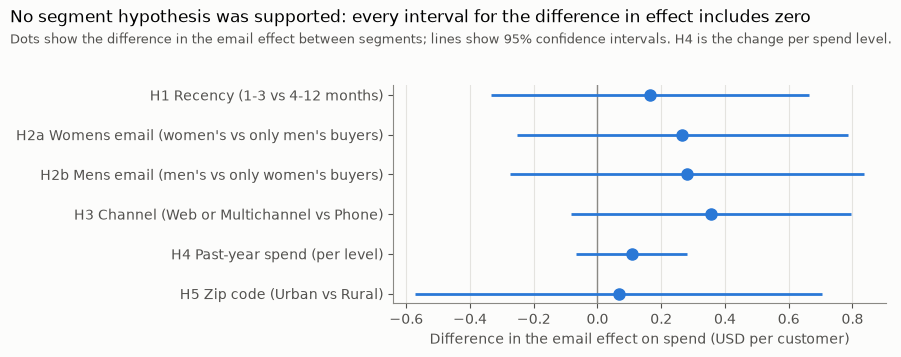

In [11]:
import matplotlib.pyplot as plt

BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "text.parse_math": False,
})

fig, ax = plt.subplots(figsize=(9, 3.6))
positions = np.arange(len(segment_tests))
ax.axvline(0, color="#8a8984", linewidth=1)
ax.hlines(positions, segment_tests["low"], segment_tests["high"], color=BLUE, linewidth=2)
ax.plot(segment_tests["value"], positions, "o", color=BLUE, markersize=8)
ax.set_yticks(positions, labels=segment_tests.index)
ax.invert_yaxis()
ax.set_xlabel("Difference in the email effect on spend (USD per customer)")
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
fig.suptitle("No segment hypothesis was supported: every interval for the difference in effect includes zero",
             x=0.01, ha="left", fontsize=12)
fig.text(0.01, 0.885, "Dots show the difference in the email effect between segments; lines show 95% confidence intervals. "
         "H4 is the change per spend level.", ha="left", fontsize=9, color="#52514e")
plt.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig("../reports/figures/segment_interactions.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the chart:** every interval crosses zero. All six estimates are positive, in the direction each hypothesis predicted, but the tests share customers, so the six signs are not independent evidence and are not counted as a pattern. **The email raised spend in almost every segment, and the data cannot show that it worked better in any of them.** The exceptions, the Womens email for customers who bought only men's merchandise and spend levels 3 and 4, are not significant on their own, which does not show that the email failed there. The intervals are wide, so differences of several tens of cents per customer cannot be ruled out either. H4 is on a different scale from the others, because it is the change per spend level.